In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility

np.random.seed(42)

# Generate sample data

n = 500
x = np.random.normal(0, 1, n)
y = 2*x + np.random.normal(0, 1, n)

# Add some outliers

outliers_x = np.random.uniform(-5, 5, 20)
outliers_y = np.random.uniform(-10, 10, 20)

x = np.concatenate([x, outliers_x])
y = np.concatenate([y, outliers_y])

# Create a DataFrame

df = pd.DataFrame({'x': x, 'y': y})

# Calculate z-scores for both x and y

z_scores = np.abs((df - df.mean()) / df.std())

# Define outliers as points with z-score > 3

outliers = (z_scores > 3).any(axis=1)

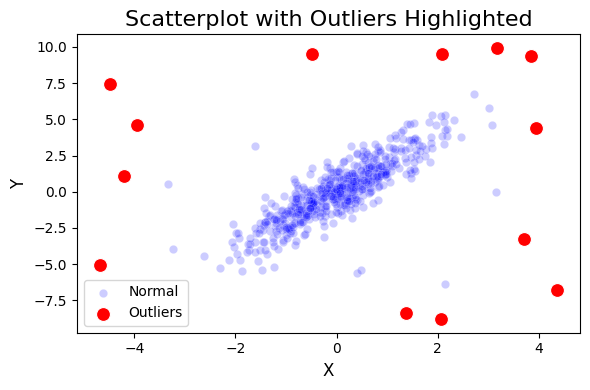

In [3]:
# Create the plot

plt.figure(figsize=(6, 4))

# Plot non-outlier points

sns.scatterplot(data=df[~outliers], x='x', y='y', color='blue', alpha=0.2)

# Plot outlier points in red

sns.scatterplot(data=df[outliers], x='x', y='y', color='red', alpha=1, s=100)

plt.title('Scatterplot with Outliers Highlighted', fontsize=16)
plt.xlabel('X', fontsize=12)
plt.ylabel('Y', fontsize=12)
plt.legend(['Normal', 'Outliers'])

plt.tight_layout()

Mathematically, a common definition for outliers is:

$|x - \mu| > 3\sigma$

Where:
- $x$ is the data point
- $\mu$ is the mean of the distribution
- $\sigma$ is the standard deviation

# Detect Outliers:

1. **Statistical Methods**:
   - Z-score: Measures how many standard deviations away a data point is from the mean.
   - IQR (Interquartile Range) Method: Identifies outliers as points below Q1 - 1.5*IQR or above Q3 + 1.5*IQR.

2. **Visualization Techniques**:
   - Box Plots: Graphically depict groups of numerical data through their quartiles.
   - Scatter Plots: Useful for identifying outliers in two-dimensional data.

3. **Machine Learning Methods**:
   - Isolation Forest: Isolates anomalies instead of profiling normal points.
   - Local Outlier Factor (LOF): Compares the local density of a point to its neighbors.

In [7]:
import numpy as np
from scipy import stats


def detect_outliers(data, threshold=3):
    z_scores = np.abs(stats.zscore(data))
    return np.where(z_scores > threshold)[0]


# Example usage

data = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 1000]
outliers = detect_outliers(data)
print(f"Outliers found at indices: {outliers}")
print(f"Outliers found at values: {np.array(data)[outliers]}")

Outliers found at indices: [10]
Outliers found at values: [1000]


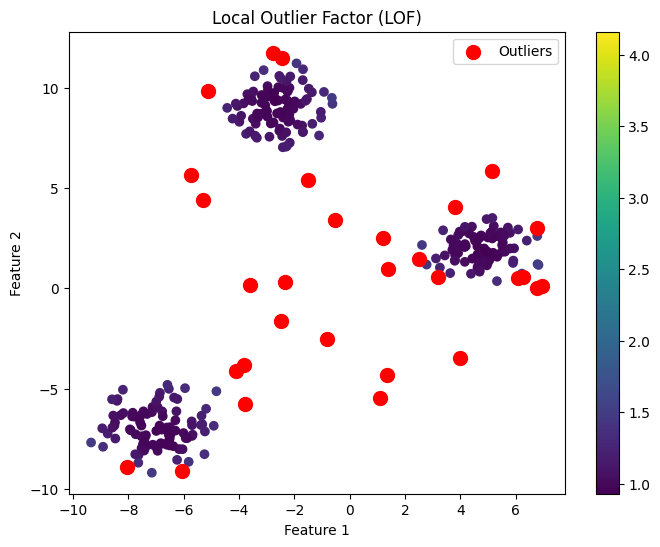

Number of outliers detected: 30


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import LocalOutlierFactor
from sklearn.datasets import make_blobs

# Generate sample data

n_samples = 300
n_outliers = 15
n_features = 2

X, _ = make_blobs(
    n_samples=n_samples - n_outliers, centers=3, n_features=n_features, random_state=42
)

# Generate outliers

rng = np.random.RandomState(42)
X = np.concatenate(
    [X, rng.uniform(low=-6, high=6, size=(n_outliers, n_features))], axis=0
)

# Fit the LOF model

clf = LocalOutlierFactor(n_neighbors=20, contamination=0.1)
y_pred = clf.fit_predict(X)
y_pred_outliers = y_pred != 1

# Calculate LOF scores

lof_scores = -clf.negative_outlier_factor_

# Plot the results

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X[:, 0], X[:, 1], c=lof_scores, cmap="viridis")
plt.colorbar(scatter)
plt.title("Local Outlier Factor (LOF)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

# Highlight the outliers

plt.scatter(
    X[y_pred_outliers, 0], X[y_pred_outliers, 1], color="red", s=100, label="Outliers"
)
plt.legend()
plt.show()

# Print number of outliers detected

print(f"Number of outliers detected: {np.sum(y_pred_outliers)}")

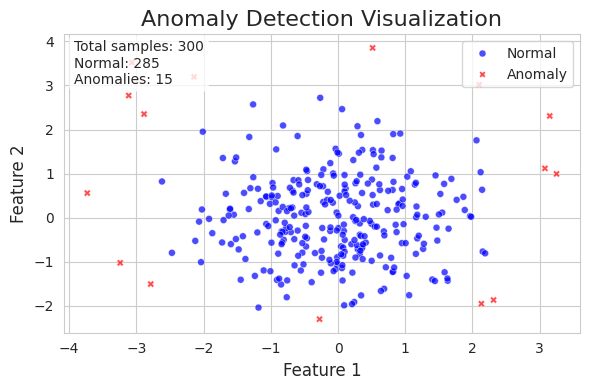

Total samples: 300
Number of normal points: 285
Number of anomalies detected: 15


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest

# Set the style for seaborn
sns.set_style("whitegrid")

# Generate synthetic data
np.random.seed(42)
n_samples = 300
n_outliers = 15
n_inliers = n_samples - n_outliers

# Generate normal data
X = np.random.randn(n_inliers, 2)

# Generate outliers
X_outliers = np.random.uniform(low=-4, high=4, size=(n_outliers, 2))

# Combine normal data and outliers
X = np.r_[X, X_outliers]

# Create a DataFrame
df = pd.DataFrame(X, columns=["Feature 1", "Feature 2"])

# Detect anomalies using Isolation Forest
clf = IsolationForest(contamination=float(n_outliers) / n_samples, random_state=42)
y_pred = clf.fit_predict(X)

# Add predictions to the DataFrame
df["Anomaly"] = y_pred
df["Anomaly"] = df["Anomaly"].map({1: "Normal", -1: "Anomaly"})

# Create the plot
plt.figure(figsize=(6, 4))

# Use Seaborn's scatterplot
sns.scatterplot(
    data=df,
    x="Feature 1",
    y="Feature 2",
    hue="Anomaly",
    palette={"Normal": "blue", "Anomaly": "red"},
    style="Anomaly",
    s=25,
    alpha=0.7,
)

# Customize the plot
plt.title("Anomaly Detection Visualization", fontsize=16)
plt.xlabel("Feature 1", fontsize=12)
plt.ylabel("Feature 2", fontsize=12)
plt.legend(title="", loc="upper right", fontsize=10)

# Add a text box with summary statistics
normal_count = df["Anomaly"].value_counts()["Normal"]
anomaly_count = df["Anomaly"].value_counts()["Anomaly"]
stats_text = (
    f"Total samples: {n_samples}\nNormal: {normal_count}\nAnomalies: {anomaly_count}"
)
plt.text(
    0.02,
    0.98,
    stats_text,
    transform=plt.gca().transAxes,
    verticalalignment="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
)

# Show the plot
plt.tight_layout()
plt.show()

# Print summary
print(f"Total samples: {n_samples}")
print(f"Number of normal points: {normal_count}")
print(f"Number of anomalies detected: {anomaly_count}")

/home/emad/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


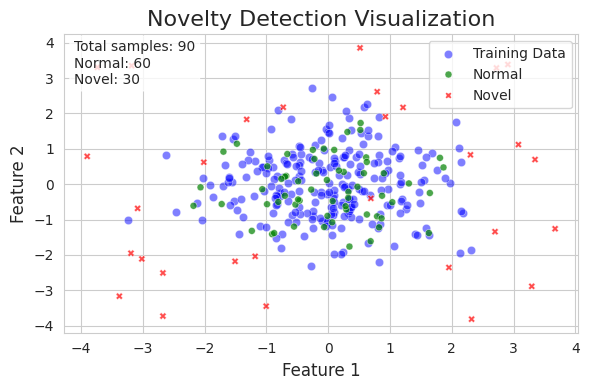

Total samples in test set: 90
Number of normal points detected: 60
Number of novel points detected: 30


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import OneClassSVM
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Set random seed for reproducibility
np.random.seed(42)

# Set the style for seaborn
sns.set_style("whitegrid")

# Generate synthetic data
n_samples = 300
n_features = 2

# Generate normal data
X_normal = np.random.randn(n_samples, n_features)

# Create a DataFrame
df_normal = pd.DataFrame(X_normal, columns=["Feature 1", "Feature 2"])

# Split data into training and testing sets
X_train, X_test = train_test_split(df_normal, test_size=0.2, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train One-Class SVM
svm = OneClassSVM(kernel="rbf", nu=0.1)
svm.fit(X_train_scaled)

# Generate some novel data
n_novel = 30
X_novel = np.random.uniform(low=-4, high=4, size=(n_novel, n_features))
X_novel_scaled = scaler.transform(X_novel)

# Combine test and novel data
X_combined = np.vstack((X_test_scaled, X_novel_scaled))

# Predict on combined data
y_pred = svm.predict(X_combined)

# Create a DataFrame with combined data and predictions
df_combined = pd.DataFrame(
    scaler.inverse_transform(X_combined), columns=["Feature 1", "Feature 2"]
)
df_combined["Type"] = ["Normal" if pred == 1 else "Novel" for pred in y_pred]

# Visualize the results
plt.figure(figsize=(6, 4))

# Plot training data
sns.scatterplot(
    data=X_train,
    x="Feature 1",
    y="Feature 2",
    color="blue",
    alpha=0.5,
    label="Training Data",
)

# Plot test and novel data
sns.scatterplot(
    data=df_combined,
    x="Feature 1",
    y="Feature 2",
    hue="Type",
    palette={"Normal": "green", "Novel": "red"},
    style="Type",
    s=25,
    alpha=0.7,
)

# Customize the plot
plt.title("Novelty Detection Visualization", fontsize=16)
plt.xlabel("Feature 1", fontsize=12)
plt.ylabel("Feature 2", fontsize=12)
plt.legend(title="", loc="upper right", fontsize=10)

# Add a text box with summary statistics
normal_count = df_combined["Type"].value_counts().get("Normal", 0)
novel_count = df_combined["Type"].value_counts().get("Novel", 0)
stats_text = (
    f"Total samples: {len(df_combined)}\nNormal: {normal_count}\nNovel: {novel_count}"
)
plt.text(
    0.02,
    0.98,
    stats_text,
    transform=plt.gca().transAxes,
    verticalalignment="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
)

# Show the plot
plt.tight_layout()
plt.show()

# Print summary
print(f"Total samples in test set: {len(X_test) + n_novel}")
print(f"Number of normal points detected: {normal_count}")
print(f"Number of novel points detected: {novel_count}")

In [14]:
from scipy import stats
import numpy as np

def detect_drift(data1, data2, threshold=0.05):
    statistic, p_value = stats.ks_2samp(data1, data2)
    if p_value < threshold:
        print(f"Data drift detected (p-value: {p_value})")
    else:
        print(f"No significant drift detected (p-value: {p_value})")

# Example usage
data1 = np.random.normal(0, 1, 1000)  # Original distribution
data2 = np.random.normal(0.5, 1, 1000)  # Shifted distribution

detect_drift(data1, data2)

Data drift detected (p-value: 1.583096794215111e-16)


Strategy For handling data irregularities:

1. **Detect**: Identify the presence and nature of irregularities in your dataset.
2. **Analyze**: Understand the cause and potential impact of these irregularities.
3. **Decide**: Choose an appropriate strategy based on the type of irregularity and your specific use case.
4. **Implement**: Apply the chosen strategy and monitor its effects.
5. **Iterate**: Continuously evaluate and refine your approach as needed.

### <a id='toc5_1_'></a>[Strategies for Handling Outliers](#toc0_)

1. **Removal**:
   - When to use: For clear data errors or when outliers significantly skew the analysis.
   - Method: Remove data points beyond a certain threshold (e.g., 3 standard deviations from the mean).

   ```python
   def remove_outliers(data, threshold=3):
       z_scores = np.abs((data - np.mean(data)) / np.std(data))
       return data[z_scores < threshold]
   ```

2. **Transformation**:
   - When to use: To reduce the impact of outliers without removing data.
   - Methods: Log transformation, Box-Cox transformation, or Winsorization.

   ```python
   def winsorize(data, limits=(0.05, 0.05)):
       return stats.mstats.winsorize(data, limits=limits)
   ```
   
3. **Capping**:
   - When to use: To limit the effect of extreme values while retaining their presence.
   - Method: Set a maximum and minimum value based on percentiles.
   
4. **Separate Analysis**:
   - When to use: When outliers represent important but rare events.
   - Method: Analyze outliers separately from the main dataset.


 


### <a id='toc5_2_'></a>[Strategies for Handling Anomalies](#toc0_)

1. **Investigation and Validation**:
   - When to use: For all detected anomalies to confirm their validity.
   - Method: Manual review or automated cross-referencing with other data sources.

2. **Isolation**:
   - When to use: When anomalies are confirmed but shouldn't be removed.
   - Method: Create separate categories or flags for anomalous data points.

3. **Adaptive Thresholding**:
   - When to use: In dynamic systems where the definition of "normal" may change over time.
   - Method: Continuously update thresholds based on recent data.

   ```python
   def adaptive_threshold(data, window_size=100, n_sigmas=3):
       rolling_mean = data.rolling(window=window_size).mean()
       rolling_std = data.rolling(window=window_size).std()
       return rolling_mean + (n_sigmas * rolling_std)
   ```
   
4. **Ensemble Methods**:
   - When to use: To improve robustness of anomaly detection.
   - Method: Combine multiple anomaly detection algorithms and use majority voting or weighted averaging.


### <a id='toc5_3_'></a>[Strategies for Handling Novelties](#toc0_)

1. **Incremental Learning**:
   - When to use: In systems where new patterns are expected to emerge over time.
   - Method: Use algorithms that can learn continuously from new data.

   ```python
   from river import linear_model

   model = linear_model.PARegressor()
   for x, y in stream:
       y_pred = model.predict_one(x)
       model = model.learn_one(x, y)
   ```
   
2. **Model Retraining**:
   - When to use: When significant new patterns are detected.
   - Method: Periodically retrain the model on recent data including novelties.

3. **Novelty Incorporation**:
   - When to use: When novelties represent important new categories or trends.
   - Method: Create new categories or features to represent the novelties.

4. **Adaptive Feature Extraction**:
   - When to use: In high-dimensional data where novelties may be complex patterns.
   - Method: Use adaptive feature extraction techniques to capture evolving patterns.


### <a id='toc5_4_'></a>[Strategies for Handling Data Drift](#toc0_)

1. **Sliding Window**:
   - When to use: For gradual drift in time-series data.
   - Method: Train on a moving window of recent data.

   ```python
   def sliding_window_train(model, X, y, window_size):
       for i in range(len(X) - window_size):
           X_window = X[i:i+window_size]
           y_window = y[i:i+window_size]
           model.fit(X_window, y_window)
   ```

2. **Weighted Samples**:
   - When to use: To give more importance to recent data while retaining some older information.
   - Method: Assign higher weights to more recent samples during training.

3. **Ensemble with Experts**:
   - When to use: When different types of drift may occur.
   - Method: Maintain multiple models trained on different time periods and use the best performing one.

4. **Concept Evolution Tracking**:
   - When to use: In systems with recurring concepts or seasonal patterns.
   - Method: Track and store different "concepts" and switch between them as needed.